# Diabetes Health Indicators (BRFSS 2021)
Data: CDC BRFSS 2021 telephone survey (cleaned Kaggle version), 236,378 respondents, 21 features.
The model will be binary classification, Diabetes_binary (0 = no diabetes or prediabetes, 1 = diabetes). so prediabetes is considered no diabetes

Model: XGBoost



1. Duplicates: Drop the 13,135 exact duplicate rows; keep profiles that appear with both labels. TO avoid identical rows landing in both train and test.
2. Missing values: None
3. Encoding and scaling are not needed: XGBoost uses ordinal codes directly and ignores scale.
4. Split: Stratified 80/20 hold-out + stratified 5-fold Cross-Validation on the 80%.  CV used for hyperparameter tuning and choosing the decision threshold.
5. Imbalance + Class weights + decision-threshold tuning: report ROC-AUC, recall, F1


In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, StratifiedKFold

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
RANDOM_STATE = 42
TARGET = 'Diabetes_binary'

# Colour palette (colour-blind-safe pair for the two classes + neutral chart chrome)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
CLASS_COLORS = {0: BLUE, 1: ORANGE}
CLASS_NAMES = {0: 'No diabetes', 1: 'Diabetes'}
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#eef5fd', '#b7d3f6', '#6da7ec', '#2a78d6', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div_blue_red', ['#184f95', '#6da7ec', '#f0efec', '#ec8a89', '#b83232'])

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.size': 10, 'font.family': 'sans-serif',
    'text.color': INK, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'axes.edgecolor': AXIS, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False, 'legend.fontsize': 9,
})

## 1. Load data and codebook
All columns are whole numbers stored as floats, so they are cast to `int`.

In [2]:
df = pd.read_csv('diabetes_binary_health_indicators_BRFSS2021.csv')
df = df.astype(int)
FEATURES = [c for c in df.columns if c != TARGET]
print('binary file:', df.shape)
df.head()

binary file: (236378, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,1,15,1,0,0,0,1,1,0,1,0,5,10,20,0,0,11,4,5
1,1,1,0,1,28,0,0,1,0,1,0,0,1,0,2,0,0,0,0,11,4,3
2,1,1,1,1,33,0,0,0,1,1,1,0,1,0,2,10,0,0,0,9,4,7
3,1,0,1,1,29,0,1,1,1,1,1,0,1,0,5,0,30,1,1,12,3,4
4,0,0,0,1,24,1,0,0,0,0,0,0,1,0,3,0,0,1,1,13,5,6


In [3]:
# Feature groups
BINARY = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity',
          'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
ORDINAL = ['GenHlth', 'Age', 'Education', 'Income']
COUNT = ['MentHlth', 'PhysHlth']# days in the past 30 with poor mental / physical health
CONTINUOUS = ['BMI']
assert sorted(BINARY + ORDINAL + COUNT + CONTINUOUS) == sorted(FEATURES)

LABELS = {
    'GenHlth': ['Excellent', 'Very good', 'Good', 'Fair', 'Poor'],
    'Age': ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59',
            '60-64', '65-69', '70-74', '75-79', '80+'],
    'Education': ['None/K', 'Gr 1-8', 'Gr 9-11', 'Gr 12/GED', 'College 1-3y', 'College 4y+'],
    'Income': ['<10k', '10-15k', '15-20k', '20-25k', '25-35k', '35-50k', '50-75k',
               '75-100k', '100-150k', '150-200k', '200k+'],   # 2021 BRFSS uses 11 income levels
}

## 2. Data quality
### 2.1 Types, ranges and missing values

In [4]:
ftype = {**{c: 'binary' for c in BINARY}, **{c: 'ordinal' for c in ORDINAL},
         **{c: 'count (0-30 days)' for c in COUNT}, **{c: 'continuous' for c in CONTINUOUS}}
quality = pd.DataFrame({
    'type': pd.Series(ftype), 'min': df[FEATURES].min(), 'max': df[FEATURES].max(),
    'n_unique': df[FEATURES].nunique(), 'missing': df[FEATURES].isna().sum(),
    'pct_most_common': (df[FEATURES].apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1),
}).loc[FEATURES]
print('Total missing values:', df.isna().sum().sum())
quality

Total missing values: 0


,type,min,max,n_unique,missing,pct_most_common
HighBP,binary,0,1,2,0,58.1
HighChol,binary,0,1,2,0,59.8
CholCheck,binary,0,1,2,0,96.3
BMI,continuous,12,99,84,0,9.2
Smoker,binary,0,1,2,0,58.8
Stroke,binary,0,1,2,0,96.1
HeartDiseaseorAttack,binary,0,1,2,0,91.3
PhysActivity,binary,0,1,2,0,77.9
Fruits,binary,0,1,2,0,62.1
Veggies,binary,0,1,2,0,82.8


there are no missing values. There are near-constant columns: CholCheck (96% = 1), AnyHealthcare (96% = 1), Stroke (96% = 0), HvyAlcoholConsump (94% = 0) and NoDocbcCost (94% = 0). They carry little information on their own, but trees handle them fine. Income has 11 levels in 2021 (8 in 2015), because CDC added brackets above $75k.
### 2.2 Duplicates

In [5]:
dup_copy = df.duplicated(keep='first') # extra copies beyond the first occurrence
print(f'Exact duplicate rows (extra copies): {dup_copy.sum():,} ({dup_copy.mean():.1%} of rows)')
print(f'Diabetes rate, all rows:              {df[TARGET].mean():.1%}')
print(f'Diabetes rate, among duplicate copies: {df.loc[dup_copy, TARGET].mean():.1%}')

show = ['Age', 'BMI', 'GenHlth', 'Income', 'Education', 'HighBP', 'HighChol', 'PhysActivity', 'MentHlth', 'PhysHlth', TARGET]
top = df.value_counts().head(5).rename('copies').reset_index()
top['Age'] = top['Age'].map(lambda a: LABELS['Age'][a - 1])
top['GenHlth'] = top['GenHlth'].map(lambda g: LABELS['GenHlth'][g - 1])
print('\nMost repeated profiles:')
top[show + ['copies']]

Exact duplicate rows (extra copies): 13,135 (5.6% of rows)
Diabetes rate, all rows:              14.2%
Diabetes rate, among duplicate copies: 1.3%

Most repeated profiles:


,Age,BMI,GenHlth,Income,Education,HighBP,HighChol,PhysActivity,MentHlth,PhysHlth,Diabetes_binary,copies
0,50-54,21,Excellent,11,6,0,0,1,0,0,0,14
1,40-44,23,Excellent,9,6,0,0,1,0,0,0,14
2,40-44,23,Excellent,11,6,0,0,1,0,0,0,14
3,65-69,24,Excellent,11,6,0,0,1,0,0,0,13
4,35-39,22,Excellent,9,6,0,0,1,0,0,0,13


In [6]:
dedup = df.drop_duplicates()
n_lab = dedup.groupby(FEATURES)[TARGET].transform('nunique')
print(f'Profiles that appear with BOTH labels: {(n_lab > 1).sum() // 2:,} profiles ({(n_lab > 1).sum():,} rows)')

Profiles that appear with BOTH labels: 1,249 profiles (2,498 rows)


The duplicates are not random. They are most likily participants that have the same answers to the suvey

Decided to drop exact duplicates ( only keeping the first copy).
- It stops identical rows from appearing in both train and test.
- Dataset size isn't affect by it. 223k rows remain.
- Side effect: the diabetes rate rises from 14.2% to 15.0%, and some easy negatives are removed.

The 1,249 profiles that appear with both labels are kept. They have same answers, but different outcomes.

In [7]:
df = df.drop_duplicates().reset_index(drop=True)
BASE = df[TARGET].mean() * 100
print(f'After de-duplication: {len(df):,} rows | diabetes = {df[TARGET].sum():,} ({BASE:.1f}%)')

After de-duplication: 223,243 rows | diabetes = 33,395 (15.0%)


### 2.3 Outliers
Only BMI is continuous. BMI 40 to 50 is real severe obesity, not an outlier. Values above about 70 come from self-reported height and weight and are not likely, but there are very few of them.

In [8]:
q1, q3 = df.BMI.quantile([.25, .75])
fence = q3 + 1.5 * (q3 - q1)
print(df.BMI.describe(percentiles=[.01, .25, .5, .75, .99]).round(1).to_string())
print(f'\nIQR upper fence = {fence:.1f} -> {(df.BMI > fence).sum():,} rows flagged')
print(f'BMI > 60: {(df.BMI > 60).sum():,} rows | BMI > 70: {(df.BMI > 70).sum():,} rows')

count    223243.0
mean         29.1
std           6.6
min          12.0
1%           18.0
25%          25.0
50%          28.0
75%          32.0
99%          50.0
max          99.0

IQR upper fence = 42.5 -> 9,291 rows flagged
BMI > 60: 411 rows | BMI > 70: 124 rows


**Decision:** keep BMI as is. XGBoost splits on thresholds, so a split at "BMI > 45" treats 50 and 99 the same and extreme values cannot distort the model.

## 3. Target distribution

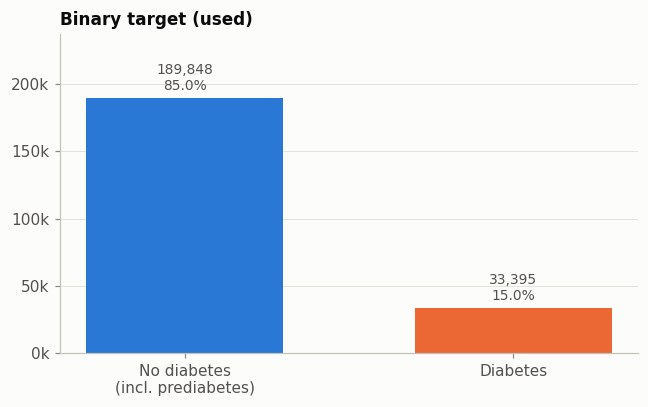

Imbalance ratio (binary): 5.68 : 1


In [9]:
b = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.8))
names = ['No diabetes\n(incl. prediabetes)', 'Diabetes']
colors = [BLUE, ORANGE]
ax.bar(range(len(b)), b.values, color=colors, width=0.6)
for i, v in enumerate(b.values):
    ax.text(
        i,
        v + b.max() * 0.02,
        f'{v:,}\n{v / b.sum():.1%}',
        ha='center',
        va='bottom',
        fontsize=9,
        color=INK2
    )
ax.set_xticks(range(len(b)), names)
ax.set_ylim(0, b.max() * 1.25)
ax.yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda v, _: f'{v / 1000:.0f}k')
)
ax.grid(axis='x', visible=False)
ax.set_title('Binary target (used)')
fig.tight_layout()
plt.show()
print(f'Imbalance ratio (binary): {b[0] / b[1]:.2f} : 1')

The binary target is about **85 / 15**. A model that always predicts "no diabetes" scores about 85% accuracy, so **accuracy is not a useful headline metric** here. In the 2021 three-class file, prediabetes is only 2.4%, which is why the binary task is the main one.

## 4. Univariate analysis
### 4.1 Binary features

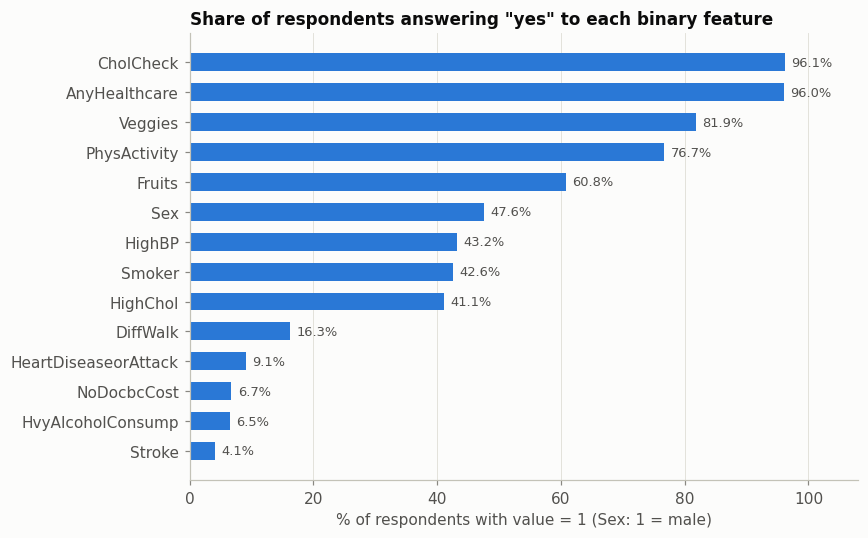

In [10]:
prev = (df[BINARY].mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(prev.index, prev.values, color=BLUE, height=0.6)
for i, v in enumerate(prev.values):
    ax.text(v + 1, i, f'{v:.1f}%', va='center', fontsize=8.5, color=INK2)
ax.set_xlim(0, 108); ax.grid(axis='y', visible=False)
ax.set_xlabel('% of respondents with value = 1 (Sex: 1 = male)')
ax.set_title('Share of respondents answering "yes" to each binary feature')
fig.tight_layout(); plt.show()

### 4.2 Ordinal features

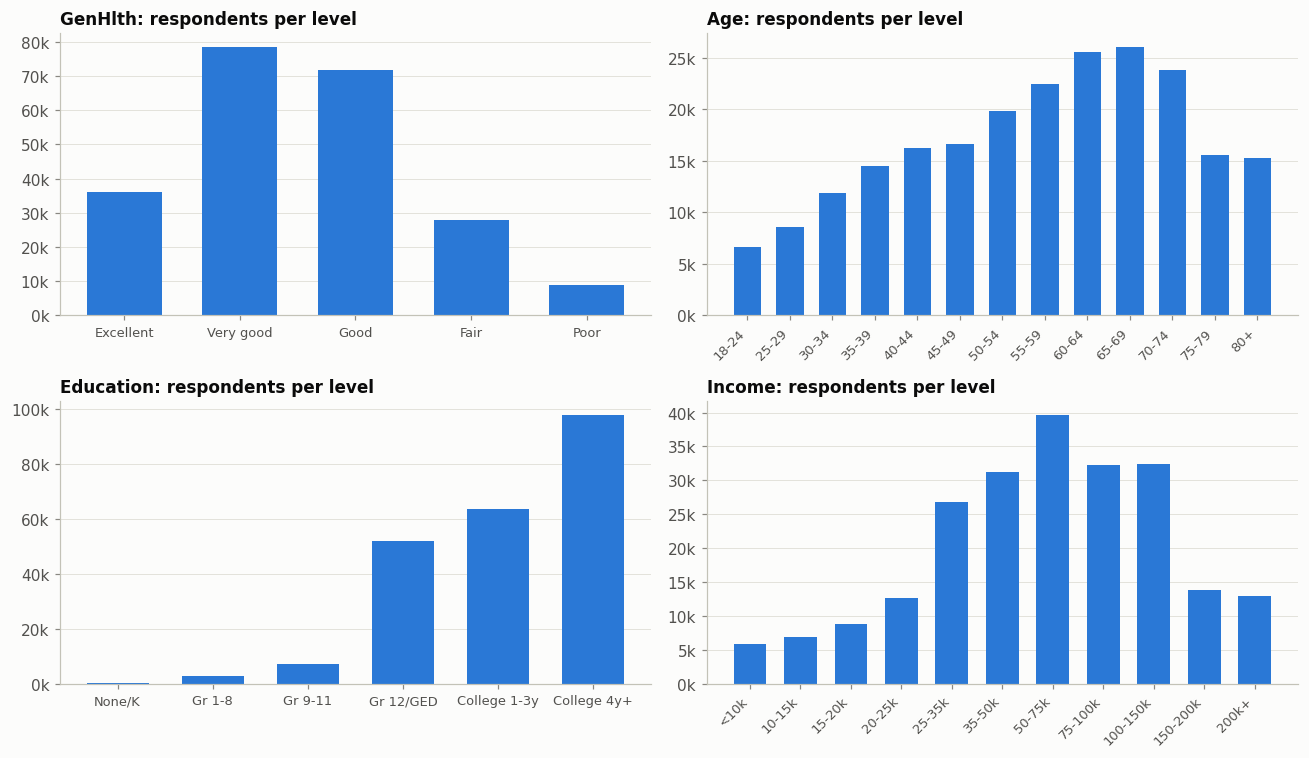

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), ORDINAL):
    vc = df[col].value_counts().sort_index()
    ax.bar(range(len(vc)), vc.values, color=BLUE, width=0.65)
    ax.set_xticks(range(len(vc)), LABELS[col], rotation=45 if col in ('Age', 'Income') else 0,
                  ha='right' if col in ('Age', 'Income') else 'center', fontsize=8.5)
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v / 1000:.0f}k'))
    ax.grid(axis='x', visible=False)
    ax.set_title(f'{col}: respondents per level')
fig.tight_layout(); plt.show()

Respondents skew older (the 55-74 bands are the largest) and more educated. The largest income group is $50-75k (level 7). Education level 1 is very small (147 rows).

### 4.3 BMI

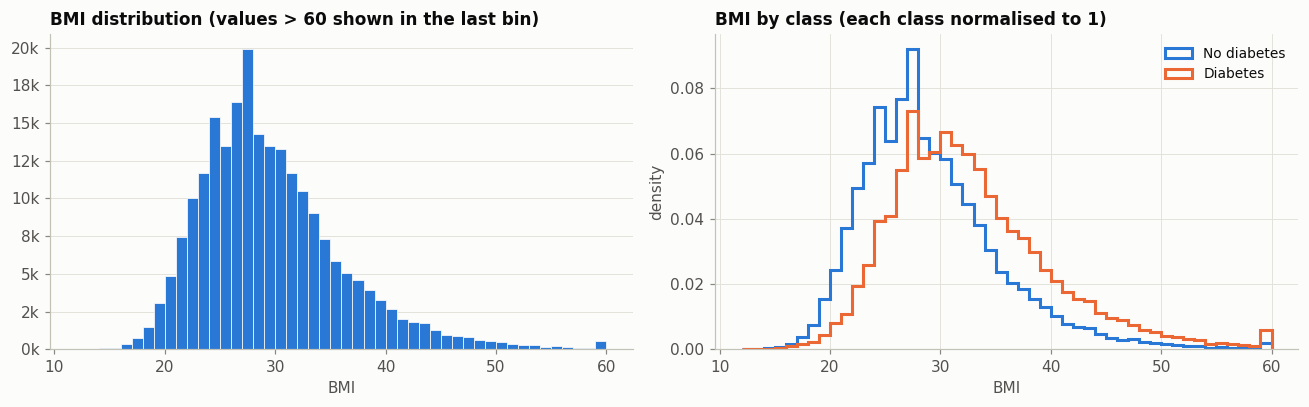

                    count  mean  std   min   25%   50%   75%   max
Diabetes_binary                                                   
No diabetes      189848.0  28.6  6.4  12.0  24.0  27.0  32.0  98.0
Diabetes          33395.0  32.2  7.4  13.0  27.0  31.0  36.0  99.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.arange(12, 61, 1)
axes[0].hist(df.BMI.clip(upper=60), bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[0].set_title('BMI distribution (values > 60 shown in the last bin)')
axes[0].set_xlabel('BMI'); axes[0].grid(axis='x', visible=False)
axes[0].yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v / 1000:.0f}k'))

for k in [0, 1]:
    axes[1].hist(df.loc[df[TARGET] == k, 'BMI'].clip(upper=60), bins=bins, density=True,
                 histtype='step', lw=2, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
axes[1].set_title('BMI by class (each class normalised to 1)')
axes[1].set_xlabel('BMI'); axes[1].set_ylabel('density'); axes[1].legend()
fig.tight_layout(); plt.show()
print(df.groupby(TARGET).BMI.describe().round(1).rename(index=CLASS_NAMES))

BMI is right-skewed (median 28). The diabetes curve sits clearly to the right: the median BMI is about 4 points higher for people with diabetes.

### 4.4 Mental and physical health days

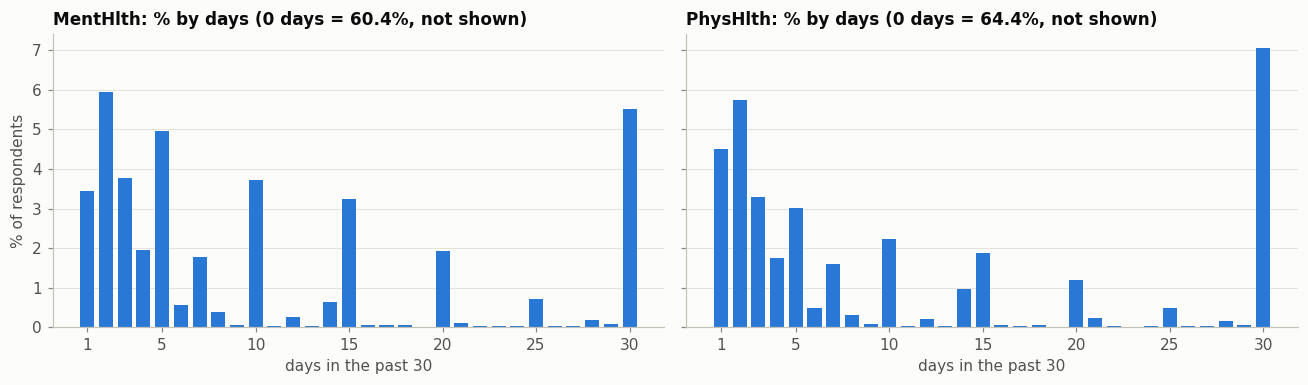

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, col in zip(axes, COUNT):
    share = df[col].value_counts(normalize=True).sort_index() * 100
    ax.bar(share.index[1:], share.values[1:], color=BLUE, width=0.75)
    ax.set_title(f'{col}: % by days (0 days = {share[0]:.1f}%, not shown)')
    ax.set_xlabel('days in the past 30'); ax.grid(axis='x', visible=False)
    ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
axes[0].set_ylabel('% of respondents')
fig.tight_layout(); plt.show()

Both are zero-inflated (60% and 64% report 0 days). They also show heaping: spikes at 5, 10, 15, 20 and 30 days, because people round their answers. Trees handle this shape without any transformation.

## 5. Bivariate analysis: each feature vs. the target
The overall diabetes rate (15.0%) is drawn as a dashed reference line.

### 5.1 Binary features: diabetes rate when the feature is 0 vs. 1

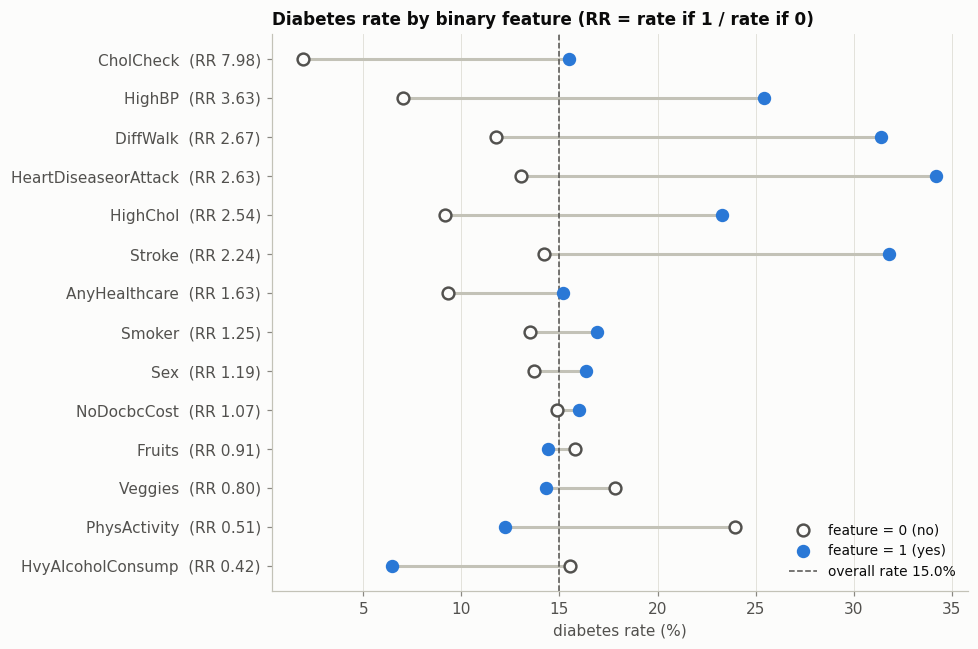

,feature,rate_if_0,rate_if_1,relative_risk
0,HvyAlcoholConsump,15.55,6.48,0.42
1,PhysActivity,23.94,12.23,0.51
2,Veggies,17.82,14.33,0.80
3,Fruits,15.79,14.42,0.91
4,NoDocbcCost,14.88,15.99,1.07
5,Sex,13.71,16.34,1.19
6,Smoker,13.51,16.91,1.25
7,AnyHealthcare,9.32,15.19,1.63
8,Stroke,14.23,31.82,2.24
9,HighChol,9.17,23.26,2.54


In [14]:
rows = []
for c in BINARY:
    r = df.groupby(c)[TARGET].mean() * 100
    rows.append({'feature': c, 'rate_if_0': r[0], 'rate_if_1': r[1], 'relative_risk': r[1] / r[0]})
rr = pd.DataFrame(rows).sort_values('relative_risk').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(rr))
ax.hlines(y, rr.rate_if_0, rr.rate_if_1, color=AXIS, lw=2, zorder=1)
ax.scatter(rr.rate_if_0, y, s=60, color=SURFACE, edgecolor=INK2, lw=1.6, zorder=3, label='feature = 0 (no)')
ax.scatter(rr.rate_if_1, y, s=60, color=BLUE, zorder=3, label='feature = 1 (yes)')
ax.axvline(BASE, color=INK2, lw=1, ls='--', label=f'overall rate {BASE:.1f}%')
ax.set_yticks(y, [f'{f}  (RR {v:.2f})' for f, v in zip(rr.feature, rr.relative_risk)])
ax.set_xlabel('diabetes rate (%)'); ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
ax.set_title('Diabetes rate by binary feature (RR = rate if 1 / rate if 0)')
fig.tight_layout(); plt.show()
rr.round(2)

- Strongest risk factors: HighBP (RR 3.6), then DiffWalk, HeartDiseaseorAttack, HighChol and Stroke (RR 2.2 to 2.7).
- CholCheck RR of 8.0 stands out. People with no cholesterol check in 5 years rarely see a doctor, so they are rarely diagnosed. Undiagnosed diabetics sit in class 0. This is label bias, not leakage.
- HvyAlcoholConsump (RR 0.42) and PhysActivity (RR 0.51), The alcohol effect is almost certainly confounding, so describe it as an association, not a cause.
- AnyHealthcare (RR 1.6) shows the same diagnosis effect as CholCheck: people without health coverage are less likely to be diagnosed.
- Fruits, Veggies, Smoker, Sex and NoDocbcCost barely move the rate.

### 5.2 Ordinal features: diabetes rate per level

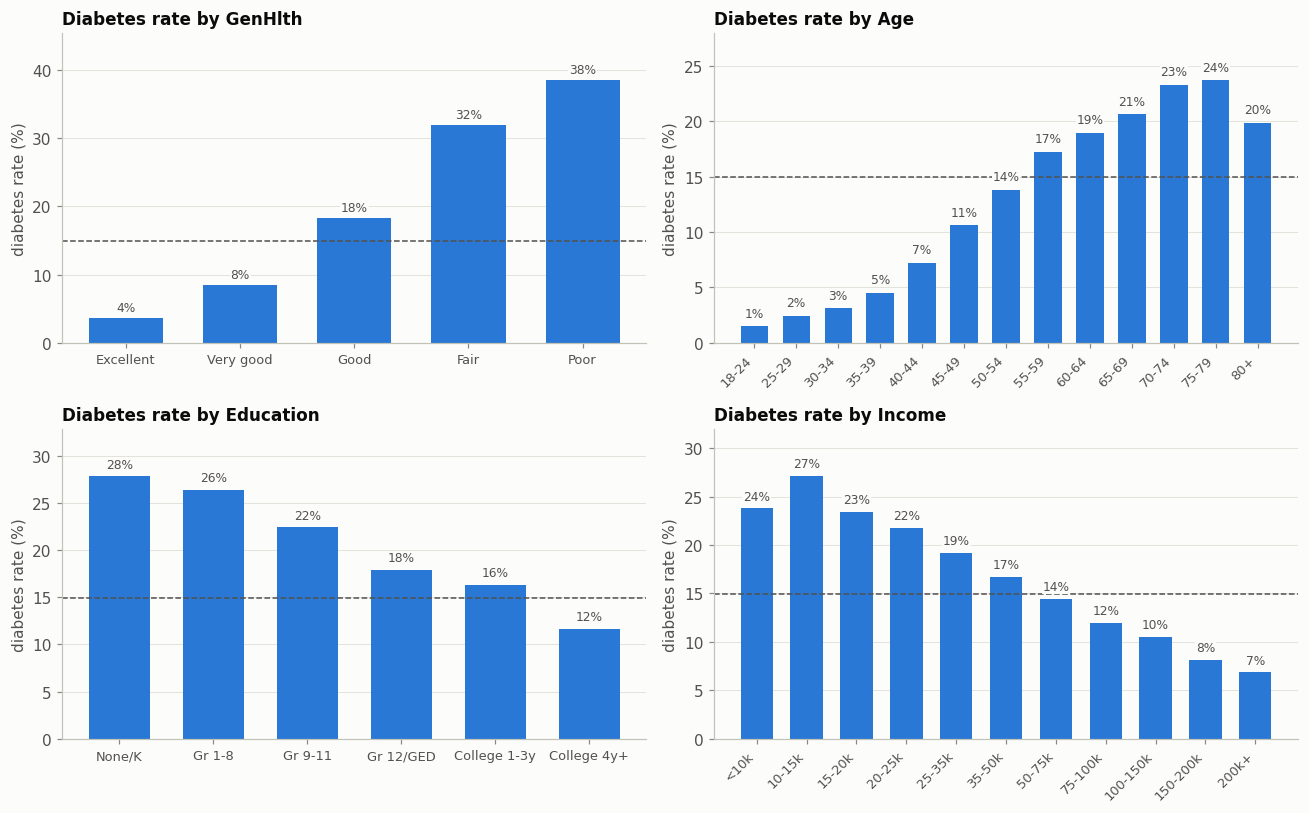

In [15]:
def rate_bars(ax, data, col, labels, title, annotate=True, rot=0):
    r = data.groupby(col)[TARGET].mean() * 100
    x = np.arange(len(r))
    ax.bar(x, r.values, color=BLUE, width=0.65)
    ax.axhline(BASE, color=INK2, lw=1, ls='--')
    if annotate:
        for i, v in enumerate(r.values):
            ax.text(i, v + 0.6, f'{v:.0f}%', ha='center', va='bottom', fontsize=8, color=INK2,
                    bbox=dict(facecolor=SURFACE, edgecolor='none', pad=0.6))
    ax.set_xticks(x, labels, rotation=rot, ha='right' if rot else 'center', fontsize=8.5)
    ax.set_ylim(0, r.max() * 1.18); ax.grid(axis='x', visible=False)
    ax.set_ylabel('diabetes rate (%)'); ax.set_title(title)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, col in zip(axes.ravel(), ORDINAL):
    rate_bars(ax, df, col, LABELS[col], f'Diabetes rate by {col}', rot=45 if col in ('Age', 'Income') else 0)
fig.tight_layout(); plt.show()

- GenHlth has the steepest gradient: from 4% ("Excellent") to 38% ("Poor").
- Age rises steadily to a peak of 24% at 75-79, then falls to 20% at 80+.
- Income and Education, both show a clear socioeconomic gradient: lower income or education means a higher rate. Income goes from 24-27% in the lowest brackets to 7% at $200k+; Education from 26-28% at the bottom to 12% for college graduates. The new 2021 brackets above $75k continue the gradient, so the extra levels add information.
- All four are monotonic or close to it, so keeping them as ordinal integers (no one-hot encoding) is better.

### 5.3 BMI and health-days vs. the target

/var/folders/1s/ygk233j567l3qg_5k36vlwpw0000gn/T/ipykernel_14002/3320020287.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  r = data.groupby(col)[TARGET].mean() * 100
/var/folders/1s/ygk233j567l3qg_5k36vlwpw0000gn/T/ipykernel_14002/3320020287.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  r = data.groupby(col)[TARGET].mean() * 100
/var/folders/1s/ygk233j567l3qg_5k36vlwpw0000gn/T/ipykernel_14002/3320020287.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt t

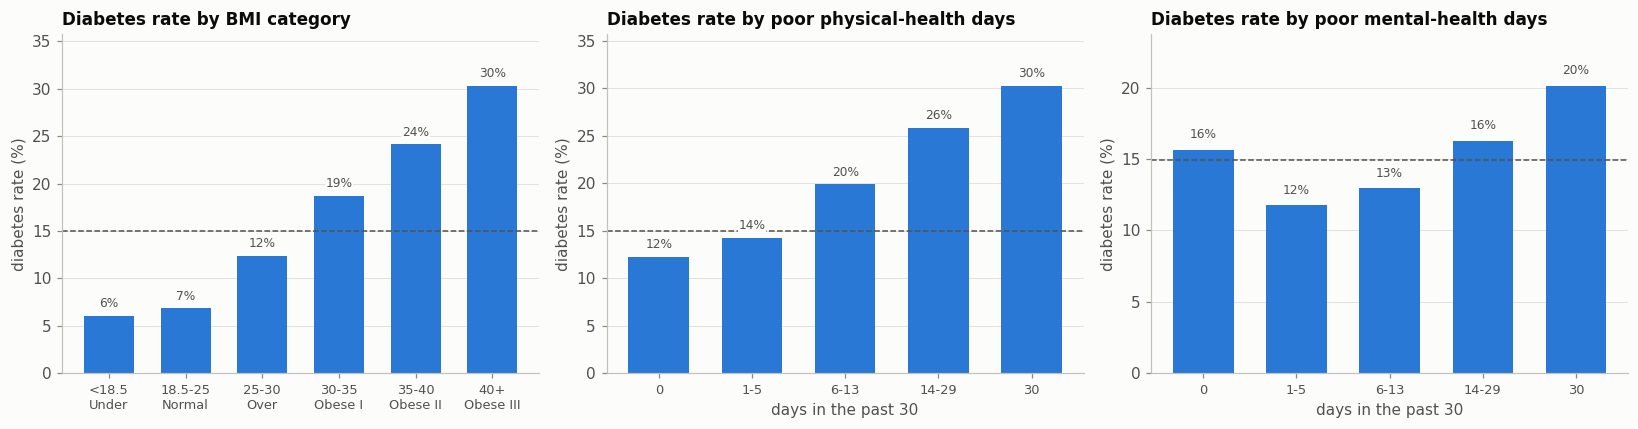

In [16]:
d = df.copy()
d['BMI_cat'] = pd.cut(d.BMI, [0, 18.5, 25, 30, 35, 40, 100], right=False,
                      labels=['<18.5\nUnder', '18.5-25\nNormal', '25-30\nOver', '30-35\nObese I', '35-40\nObese II', '40+\nObese III'])
day_bins, day_labels = [-1, 0, 5, 13, 29, 30], ['0', '1-5', '6-13', '14-29', '30']
for c in COUNT:
    d[c + '_bin'] = pd.cut(d[c], day_bins, labels=day_labels)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rate_bars(axes[0], d, 'BMI_cat', d.BMI_cat.cat.categories, 'Diabetes rate by BMI category')
rate_bars(axes[1], d, 'PhysHlth_bin', day_labels, 'Diabetes rate by poor physical-health days')
rate_bars(axes[2], d, 'MentHlth_bin', day_labels, 'Diabetes rate by poor mental-health days')
for ax in axes[1:]:
    ax.set_xlabel('days in the past 30')
fig.tight_layout(); plt.show()

- BMI has a strong dose-response pattern: the rate rises from about 7% at normal weight to 30% at BMI 40+.
- Physical-health days matter: 12% at 0 days vs. 30% at 30 days.
- Mental-health days are non-monotonic: the rate is 16% at 0 days, drops to 12% at 1-5 days, then rises to 20% at 30 days. Because 60% of people report 0 days, the overall signal is weak (single-feature AUC 0.51, among the lowest).

### 5.4 Ranking all features: single-feature ROC-AUC and mutual information
Each feature is scored on its own. This is considered as a leakage check: a leaked feature would score close to AUC 1.0.

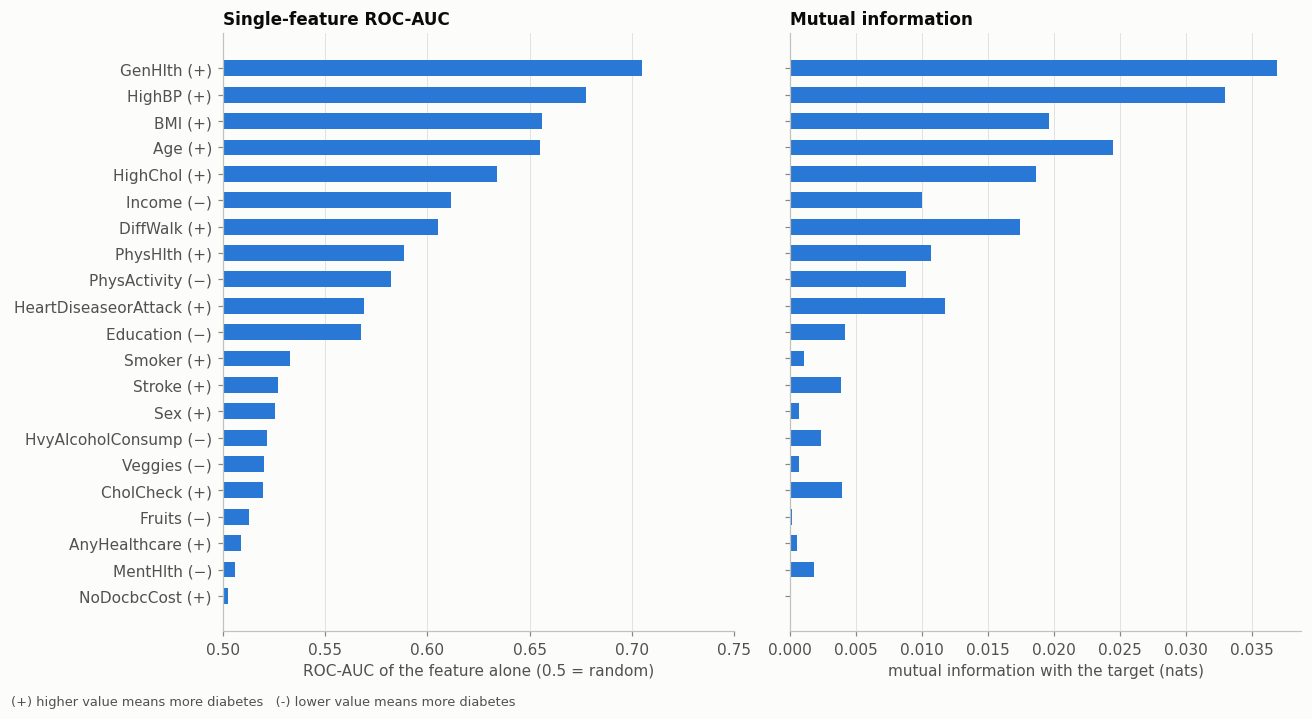

,auc,direction,mutual_info
GenHlth,0.705,+,0.037
HighBP,0.678,+,0.033
BMI,0.656,+,0.020
Age,0.655,+,0.024
HighChol,0.634,+,0.019
Income,0.612,−,0.010
DiffWalk,0.605,+,0.017
PhysHlth,0.589,+,0.011
PhysActivity,0.582,−,0.009
HeartDiseaseorAttack,0.569,+,0.012


In [17]:
auc, sign = {}, {}
for c in FEATURES:
    a = roc_auc_score(df[TARGET], df[c])
    auc[c], sign[c] = max(a, 1 - a), '+' if a >= 0.5 else '−'
mi = pd.Series(mutual_info_classif(df[FEATURES], df[TARGET], discrete_features=True,
                                   random_state=RANDOM_STATE), index=FEATURES)
strength = pd.DataFrame({'auc': pd.Series(auc), 'direction': pd.Series(sign), 'mutual_info': mi}).sort_values('auc')

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
ylab = [f'{f} ({s})' for f, s in zip(strength.index, strength.direction)]
axes[0].barh(ylab, strength.auc - 0.5, left=0.5, color=BLUE, height=0.6)
axes[0].set_xlim(0.5, 0.75); axes[0].set_xlabel('ROC-AUC of the feature alone (0.5 = random)')
axes[0].set_title('Single-feature ROC-AUC')
axes[1].barh(ylab, strength.mutual_info, color=BLUE, height=0.6)
axes[1].set_xlabel('mutual information with the target (nats)')
axes[1].set_title('Mutual information')
for ax in axes:
    ax.grid(axis='y', visible=False)
fig.text(0.01, 0.005, '(+) higher value means more diabetes   (-) lower value means more diabetes', color=INK2, fontsize=8.5)
fig.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()
strength.sort_values('auc', ascending=False).round(3)

No leakage: the best feature, GenHlth, reaches only AUC 0.70, and no feature is computed from the diagnosis. The top group is GenHlth, HighBP, BMI, Age, HighChol, Income and DiffWalk. Mutual information ranks Age above BMI, and HeartDiseaseorAttack and PhysHlth above Income.


## 6. Relationships between features
### 6.1 Spearman correlation matrix
Spearman is used because most variables are binary or ordinal.

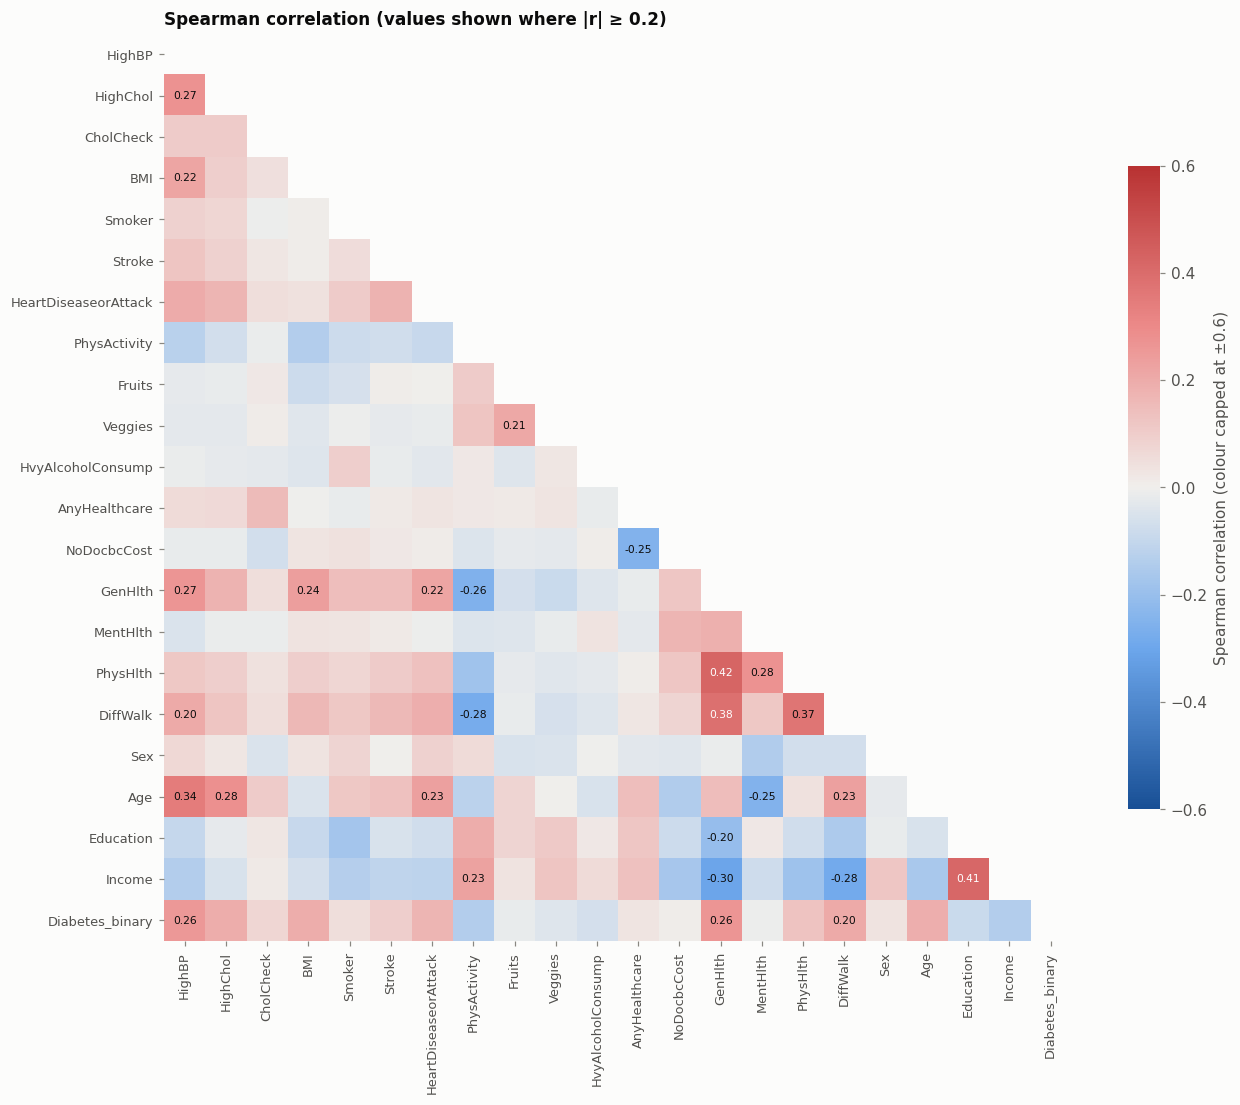

Strongest feature-feature pairs:
GenHlth    PhysHlth    0.423
Education  Income      0.414
GenHlth    DiffWalk    0.385
PhysHlth   DiffWalk    0.366
HighBP     Age         0.343
GenHlth    Income     -0.305
DiffWalk   Income     -0.283
HighChol   Age         0.279

Correlation with target:
GenHlth                 0.265
HighBP                  0.256
DiffWalk                0.203
HighChol                0.194
BMI                     0.193
Age                     0.192
HeartDiseaseorAttack    0.171
Income                 -0.139
PhysActivity           -0.139
PhysHlth                0.128
Stroke                  0.098
Education              -0.089
CholCheck               0.073
HvyAlcoholConsump      -0.063
Smoker                  0.047
Veggies                -0.038
Sex                     0.037
AnyHealthcare           0.032
Fruits                 -0.019
MentHlth               -0.009
NoDocbcCost             0.008


In [18]:
cols = FEATURES + [TARGET]
corr = df[cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(np.ma.array(corr, mask=mask), cmap=DIV, vmin=-0.6, vmax=0.6)
for i in range(len(cols)):
    for j in range(i):
        v = corr.iat[i, j]
        if abs(v) >= 0.2:
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(v) > 0.38 else INK)
ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=8.5)
ax.set_yticks(range(len(cols)), cols, fontsize=8.5)
ax.grid(False); ax.spines[['left', 'bottom']].set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7); cb.outline.set_visible(False)
cb.set_label('Spearman correlation (colour capped at ±0.6)')
ax.set_title('Spearman correlation (values shown where |r| ≥ 0.2)')
fig.tight_layout(); plt.show()

pairs = corr.loc[FEATURES, FEATURES].where(np.triu(np.ones((len(FEATURES),) * 2, dtype=bool), 1)).stack()
print('Strongest feature-feature pairs:')
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(3).to_string())
print('\nCorrelation with target:')
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

- No multicollinearity problem. The strongest pair is GenHlth–PhysHlth at 0.42. Nothing comes close to 0.8, so no feature needs dropping.
- Clusters to describe:
  - a self-rated health cluster (GenHlth, PhysHlth, DiffWalk, MentHlth)
  - a socioeconomic pair (Education–Income, 0.41)
  - a cardiometabolic group (HighBP, HighChol, Age, HeartDiseaseorAttack)
- Correlations with the target are modest (at most about 0.26). No single feature dominates, so the model has to combine many weak signals.

## 7. Multivariate patterns
### 7.1 Age × BMI

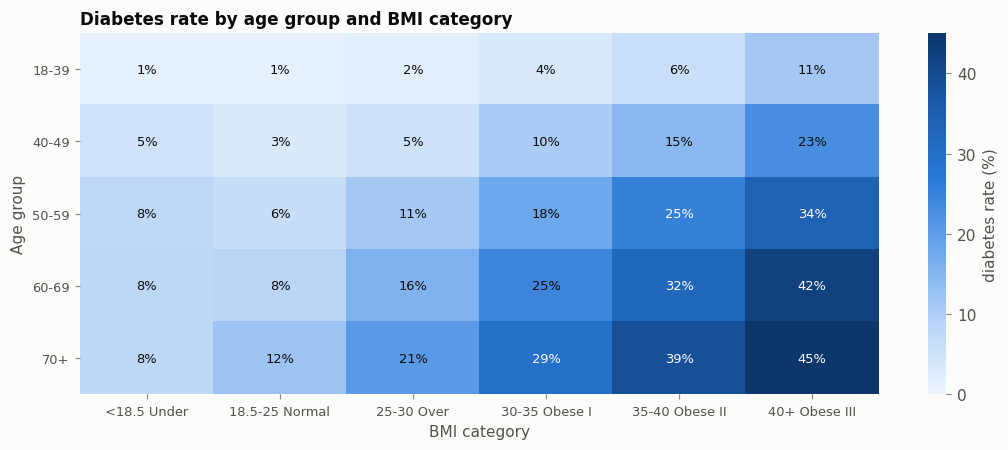

In [19]:
AGE_GROUPS = {'18-39': range(1, 5), '40-49': range(5, 7), '50-59': range(7, 9), '60-69': range(9, 11), '70+': range(11, 14)}
d['AgeGroup'] = pd.Categorical(d.Age.map({a: g for g, rng in AGE_GROUPS.items() for a in rng}), categories=list(AGE_GROUPS), ordered=True)
d['BMI_cat1'] = d.BMI_cat.cat.rename_categories(lambda s: s.replace('\n', ' '))

def rate_heatmap(ax, data, row, col, title, min_n=100):
    rate = data.pivot_table(index=row, columns=col, values=TARGET, aggfunc='mean', observed=False) * 100
    n = data.pivot_table(index=row, columns=col, values=TARGET, aggfunc='size', observed=False)
    rate = rate.where(n >= min_n)
    im = ax.imshow(rate.values, cmap=SEQ, vmin=0, vmax=np.nanmax(rate.values), aspect='auto')
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            v = rate.iat[i, j]
            ax.text(j, i, '–' if np.isnan(v) else f'{v:.0f}%', ha='center', va='center', fontsize=8.5,
                    color='white' if (not np.isnan(v) and v > np.nanmax(rate.values) * 0.55) else INK)
    ax.set_xticks(range(rate.shape[1]), rate.columns, fontsize=8.5)
    ax.set_yticks(range(rate.shape[0]), rate.index, fontsize=8.5)
    ax.set_xlabel(col.strip()); ax.set_ylabel(row.strip())
    ax.grid(False); ax.spines[['left', 'bottom']].set_visible(False)
    ax.set_title(title)
    return im

fig, ax = plt.subplots(figsize=(10, 4.2))
im = rate_heatmap(ax, d, 'AgeGroup', 'BMI_cat1', 'Diabetes rate by age group and BMI category')
ax.set_xlabel('BMI category'); ax.set_ylabel('Age group')
cb = fig.colorbar(im, ax=ax); cb.outline.set_visible(False); cb.set_label('diabetes rate (%)')
fig.tight_layout(); plt.show()

Age and BMI compound. An 18-39-year-old of normal weight is about 1% diabetic, while someone aged 70+ with BMI 40+ is at 45%. The rate rises with each factor at nearly every level of the other.

### 7.2 Cardiometabolic comorbidities

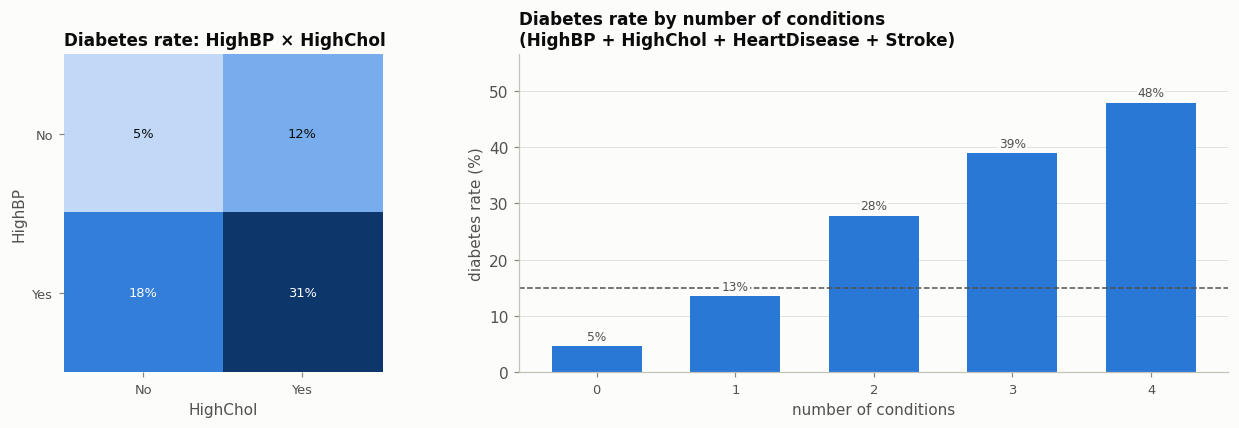

Comorbidities
0    86010
1    73357
2    49209
3    12825
4     1842


In [20]:
d['Comorbidities'] = d[['HighBP', 'HighChol', 'HeartDiseaseorAttack', 'Stroke']].sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1.4]})
d['HighBP '] = d.HighBP.map({0: 'No', 1: 'Yes'}); d['HighChol '] = d.HighChol.map({0: 'No', 1: 'Yes'})
im = rate_heatmap(axes[0], d, 'HighBP ', 'HighChol ', 'Diabetes rate: HighBP × HighChol')
axes[0].set_aspect('equal')
rate_bars(axes[1], d, 'Comorbidities', ['0', '1', '2', '3', '4'],
          'Diabetes rate by number of conditions\n(HighBP + HighChol + HeartDisease + Stroke)')
axes[1].set_xlabel('number of conditions')
fig.tight_layout(); plt.show()
print(d.Comorbidities.value_counts().sort_index().rename('n respondents').to_string())

High blood pressure and high cholesterol together give 31%, against 5% with neither. The rate rises steadily with the count of conditions, from 5% (none) to 48% (all four).
### 7.3 Income × Education

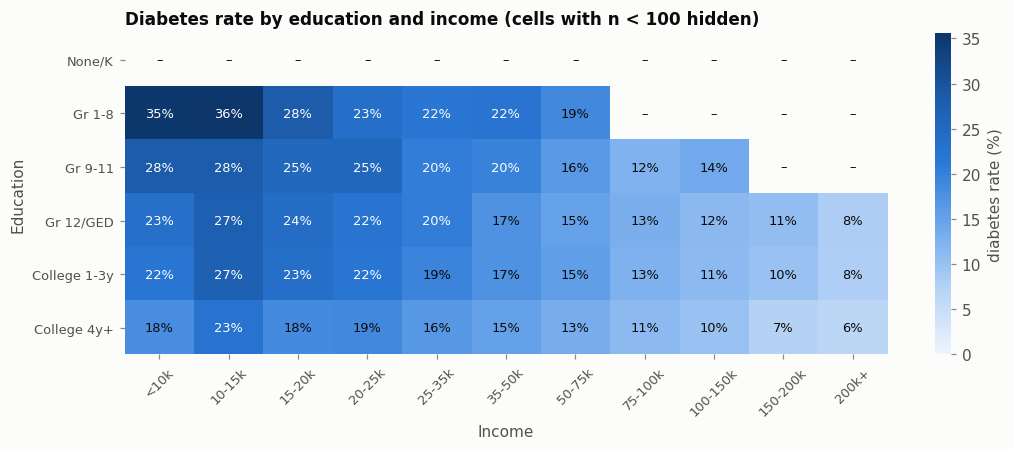

In [21]:
d['Income_lbl'] = pd.Categorical(d.Income.map(lambda v: LABELS['Income'][v - 1]), categories=LABELS['Income'], ordered=True)
d['Education_lbl'] = pd.Categorical(d.Education.map(lambda v: LABELS['Education'][v - 1]), categories=LABELS['Education'], ordered=True)
fig, ax = plt.subplots(figsize=(10, 4.2))
im = rate_heatmap(ax, d, 'Education_lbl', 'Income_lbl', 'Diabetes rate by education and income (cells with n < 100 hidden)')
ax.set_xlabel('Income'); ax.set_ylabel('Education')
ax.tick_params(axis='x', labelrotation=45)
cb = fig.colorbar(im, ax=ax); cb.outline.set_visible(False); cb.set_label('diabetes rate (%)')
fig.tight_layout(); plt.show()

## 8. Modeling: XGBoost
### 8.1 Train/test split
Stratified 80/20 so both sets keep the 15% diabetes rate. The test set is not touched until the final evaluation.

In [22]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import (confusion_matrix, classification_report, recall_score, precision_score,
                             f1_score, average_precision_score, roc_curve, precision_recall_curve)

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("train:", X_train.shape, "test:", X_test.shape)
print("diabetes rate train:", round(y_train.mean(), 3), "test:", round(y_test.mean(), 3))

train: (178594, 21) test: (44649, 21)
diabetes rate train: 0.15 test: 0.15


### 8.2 Baseline: XGBoost without handling the imbalance
Scored with stratified 5-fold CV on the training set only.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

base = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=RANDOM_STATE, n_jobs=-1)

base_prob = cross_val_predict(base, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
base_pred = (base_prob >= 0.5).astype(int)

print("roc auc:", roc_auc_score(y_train, base_prob))
print("recall:", recall_score(y_train, base_pred))
print("precision:", precision_score(y_train, base_pred))
print("f1:", f1_score(y_train, base_pred))
#at the default 0.5 threshold the model only catches 15% of diabetics
#because 85% of the rows are no diabetes so the model leans toward predicting 0
#roc auc is fine (0.81) so the model ranks people well, the problem is where we cut

roc auc: 0.8136094517314975
recall: 0.15384039526875282
precision: 0.5691732447029497
f1: 0.24221351327459706


### 8.3 Handling the imbalance: class weights
`scale_pos_weight` = number of negatives / number of positives in the training set. It makes each diabetes case count about 5.7 times more in the loss.

SMOTE / oversampling is not used: the features are binary and ordinal survey answers, so synthetic rows would be in-between values that no one can answer (e.g. HighBP = 0.4). Class weights get the same effect without creating fake data.

In [24]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", spw)

weighted = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, scale_pos_weight=spw,
                         random_state=RANDOM_STATE, n_jobs=-1)

w_prob = cross_val_predict(weighted, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
w_pred = (w_prob >= 0.5).astype(int)

print("roc auc:", roc_auc_score(y_train, w_prob))
print("recall:", recall_score(y_train, w_pred))
print("precision:", precision_score(y_train, w_pred))
print("f1:", f1_score(y_train, w_pred))
#recall jumps from 0.15 to 0.78 but precision drops from 0.57 to 0.31 (more false alarms)
#roc auc did not change, the weights move the cut point they dont make the model rank better

scale_pos_weight: 5.684907920347357
roc auc: 0.8134655399520526
recall: 0.7774367420272495
precision: 0.31176355803725553
f1: 0.4450539443093307


### 8.4 Hyperparameter tuning (stratified 5-fold CV)
Small grid on the main tree settings, scored by ROC-AUC.

In [25]:
param_grid = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1],
    "n_estimators": [200, 400],
}

grid = GridSearchCV(
    XGBClassifier(scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1),
    param_grid,
    scoring="roc_auc",
    cv=cv
)
grid.fit(X_train, y_train)

print("best params:", grid.best_params_)
print("best cv roc auc:", grid.best_score_)

pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False).head()

best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400}
best cv roc auc: 0.8138240958436281


,params,mean_test_score,std_test_score
1,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.813824,0.001543
2,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.813799,0.001312
7,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.813650,0.001357
6,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.813641,0.001434
0,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.813049,0.001682


### 8.5 Decision threshold tuning
The threshold is chosen on out-of-fold CV predictions from the training set (the test set stays unseen). We pick the threshold with the highest F1.

best threshold: 0.6177813
f1: 0.46582639975835466 recall: 0.6349752957029495 precision: 0.3678390216401405


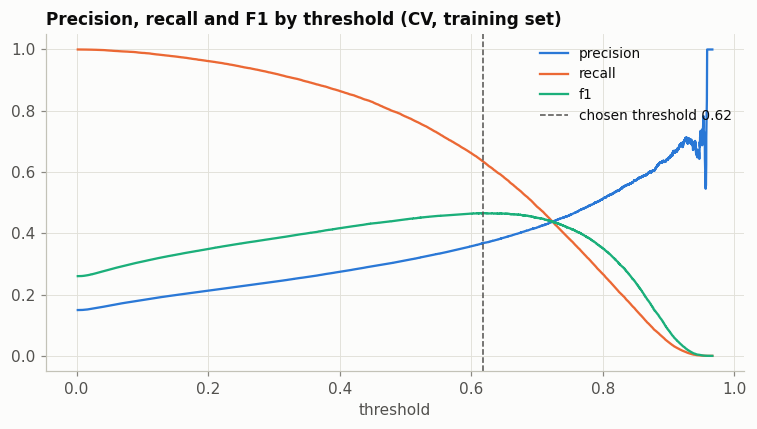

In [26]:
model = grid.best_estimator_

oof_prob = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)
f1 = 2 * precision * recall / (precision + recall)
best_i = np.nanargmax(f1[:-1])
threshold = thresholds[best_i]

print("best threshold:", threshold)
print("f1:", f1[best_i], "recall:", recall[best_i], "precision:", precision[best_i])
#f1 is almost flat between 0.5 and 0.7, so the threshold is mostly a trade between recall and precision
#a lower threshold catches more diabetics but gives more false alarms

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, precision[:-1], color=BLUE, label="precision")
ax.plot(thresholds, recall[:-1], color=ORANGE, label="recall")
ax.plot(thresholds, f1[:-1], color=AQUA, label="f1")
ax.axvline(threshold, color=INK2, ls="--", lw=1, label=f"chosen threshold {threshold:.2f}")
ax.set_xlabel("threshold"); ax.set_title("Precision, recall and F1 by threshold (CV, training set)")
ax.legend()
fig.tight_layout(); plt.show()

### 8.6 Final evaluation on the test set

In [27]:
test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype(int)

print("roc auc:", roc_auc_score(y_test, test_prob))
print("pr auc:", average_precision_score(y_test, test_prob))
print("recall:", recall_score(y_test, test_pred))
print("precision:", precision_score(y_test, test_pred))
print("f1:", f1_score(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred, target_names=["No diabetes", "Diabetes"]))

roc auc: 0.8144078845234551
pr auc: 0.42164402170342463
recall: 0.6345261266656685
precision: 0.3680097255991664
f1: 0.4658422643583402
[[30692  7278]
 [ 2441  4238]]
              precision    recall  f1-score   support

 No diabetes       0.93      0.81      0.86     37970
    Diabetes       0.37      0.63      0.47      6679

    accuracy                           0.78     44649
   macro avg       0.65      0.72      0.66     44649
weighted avg       0.84      0.78      0.80     44649



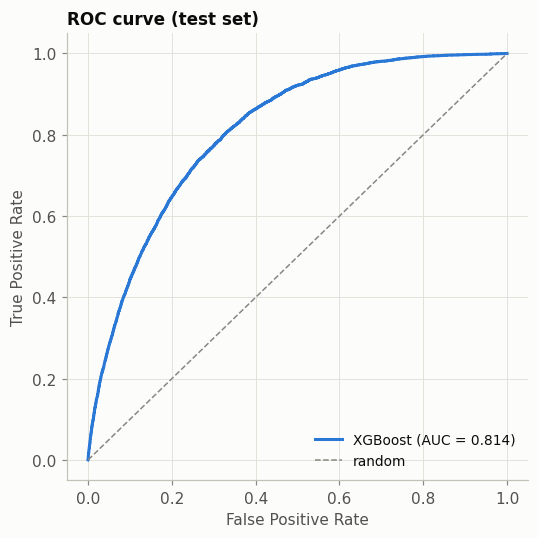

In [28]:
fpr, tpr, _ = roc_curve(y_test, test_prob)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color=BLUE, lw=2, label=f"XGBoost (AUC = {roc_auc_score(y_test, test_prob):.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="random")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curve (test set)")
ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

### 8.7 Feature importance

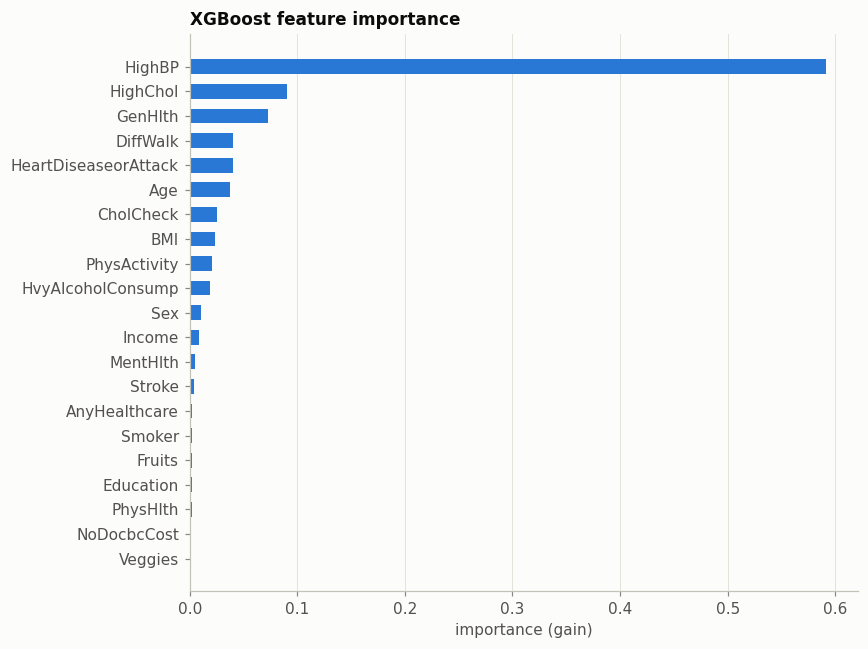

HighBP                  0.592
HighChol                0.090
GenHlth                 0.073
DiffWalk                0.040
HeartDiseaseorAttack    0.040
Age                     0.038
CholCheck               0.026
BMI                     0.023
dtype: float32

In [29]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("importance (gain)")
ax.set_title("XGBoost feature importance")
fig.tight_layout(); plt.show()
imp.sort_values(ascending=False).head(8).round(3)
#HighBP takes most of the gain because it is the first split in most of the trees
#gain favors the first split so this ranking is not the same as the eda feature ranking

### 8.8 Can we do better?
Other models scored with the same stratified 5-fold CV on the training set (ROC-AUC).

In [30]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  #harmless matmul warnings from logistic regression on mac

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

log_reg = make_pipeline(
    ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), ORDINAL)], remainder=StandardScaler()),
    LogisticRegression(max_iter=3000)
)

models = {
    "XGBoost (ours)": model,
    "LightGBM": LGBMClassifier(n_estimators=800, learning_rate=0.02, min_child_samples=100, subsample=0.8,
                               subsample_freq=1, colsample_bytree=0.6, reg_lambda=5, random_state=RANDOM_STATE, verbose=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, random_state=RANDOM_STATE),
    "CatBoost": CatBoostClassifier(iterations=1500, learning_rate=0.05, depth=6, random_seed=RANDOM_STATE, verbose=0),
    "Logistic Regression": log_reg,
}

results = {}
for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    results[name] = scores.mean()
    print(name, "cv roc auc:", round(scores.mean(), 4), "+/-", round(scores.std(), 4))
#all models land between 0.810 and 0.815, the gaps are about the same size as the +/- between folds
#a wider xgboost search (60 settings, run separately) only reached 0.8146
#adding new features (comorbidity count, BMI x Age, etc.) and blending models also did not help

XGBoost (ours) cv roc auc: 0.8138 +/- 0.0015
LightGBM cv roc auc: 0.8145 +/- 0.0017
HistGradientBoosting cv roc auc: 0.8134 +/- 0.0016
CatBoost cv roc auc: 0.8118 +/- 0.0018
Logistic Regression cv roc auc: 0.81 +/- 0.002


**Learning curve:** train the same model on more and more rows and score it on the test set.

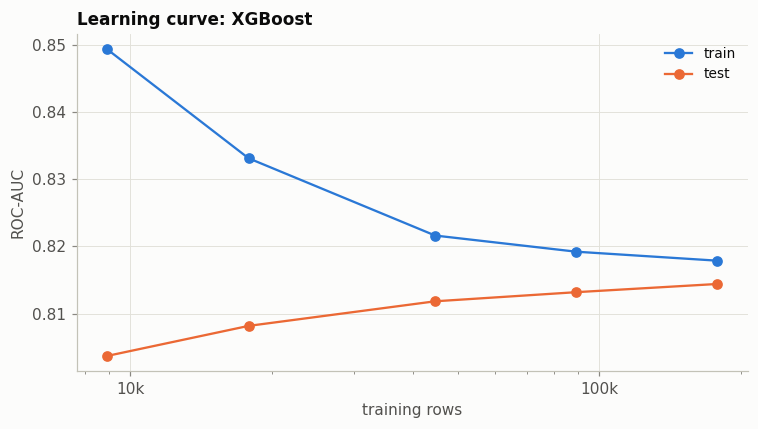

,rows,train auc,test auc
0,8930,0.8493,0.8037
1,17859,0.8331,0.8082
2,44648,0.8216,0.8118
3,89297,0.8192,0.8132
4,178594,0.8179,0.8144


In [31]:
sizes = [0.05, 0.1, 0.25, 0.5, 1.0]
train_auc, test_auc, n_rows = [], [], []

for s in sizes:
    X_part = X_train.sample(frac=s, random_state=RANDOM_STATE)
    y_part = y_train.loc[X_part.index]
    m = XGBClassifier(**grid.best_params_, scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_part, y_part)
    n_rows.append(len(X_part))
    train_auc.append(roc_auc_score(y_part, m.predict_proba(X_part)[:, 1]))
    test_auc.append(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_rows, train_auc, "o-", color=BLUE, label="train")
ax.plot(n_rows, test_auc, "o-", color=ORANGE, label="test")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.set_xlabel("training rows"); ax.set_ylabel("ROC-AUC")
ax.set_title("Learning curve: XGBoost")
ax.legend()
fig.tight_layout(); plt.show()

pd.DataFrame({"rows": n_rows, "train auc": train_auc, "test auc": test_auc}).round(4)
#the train and test lines meet at about 0.815
#doubling the data from 89k to 178k rows adds only about 0.001
#so more data or a bigger model wont help much, the limit is the data itself (self reported survey, undiagnosed diabetics in class 0)

## 9. Conclusion
- **Final model:** XGBoost (max_depth 3, learning_rate 0.05, 400 trees) with `scale_pos_weight` ≈ 5.7 and a decision threshold of 0.62 chosen on CV.
- **Test set:** ROC-AUC 0.814, PR-AUC 0.42, recall 0.63, precision 0.37, F1 0.47. The CV numbers are almost the same, so the model is not overfitting.
- **Imbalance:** without any handling the model caught only 15% of diabetics at threshold 0.5. Class weights plus threshold tuning raised recall to 63%.
- **Trade-off:** the model finds about 2 out of 3 diabetics, but about 2 out of 3 people it flags do not have diabetes. That fits a screening use, where missing a case costs more than a false alarm. If recall matters more, the threshold can be lowered (see 8.5).
- **Limits:** the data is a self-reported survey and undiagnosed diabetics sit in class 0 (see CholCheck in 5.1). Other models, a wider search, new features and blends all stay at about 0.81 to 0.815, and more data barely helps (see 8.8), so the limit is the data, not the model.